# Per-hunk context selector with a small LLM (Colab, GPU)

This notebook is the small-LLM version of `selector_training_colab.ipynb`. It asks the
same question as that notebook's **Selector B**: which diff hunks should be upgraded
from `H01_min` (the diff and the PR text) to `H03_file` (plus the whole file) within a
token budget? A small code LLM (Qwen2.5-Coder, 0.5B or 1.5B) reads each hunk's
`H01_min` text and gives a score; the hunks with the highest scores are upgraded first.

**Three ways to use the LLM**, all scored out of fold on the same folds:
1. **Zero-shot**: an instruct model is asked whether the whole file would help review
   this hunk; the score is log P("Yes") − log P("No"). No training.
2. **Frozen embeddings + logistic regression**: mean-pooled hidden states of the LLM,
   reduced with PCA inside each fold. Also combined with the tabular features.
3. **LoRA fine-tuning**: the LLM with a one-output classification head, trained with
   LoRA on the training repositories of each fold (weighted loss for the rare positives).

**Baselines**, recomputed on the same folds: tabular logistic regression (the best
Selector B of the first run), random upgrade, cheapest first, always `H01_min`,
always `H03_file`, and the hindsight ranking (an upper bound, not a method).

**Scoring** is identical to the main notebook: lookup in the saved per-hunk outcome
table, union of covered references per PR, severity weights 5 / 2 / 0.5, tokens as a
share of always `H03_file`, human and AI references reported separately.

**Runtime.** Choose a GPU runtime (Runtime → Change runtime type → T4 GPU). With the
defaults (0.5B model, 5 folds grouped by repository, 3 seeds) the whole notebook takes
roughly 30 to 45 minutes on a T4. Fine-tuning results are cached on Drive per fold, so
a disconnected run resumes where it stopped.

**Limits.** 15% of the benchmark, one reviewer run, and only 37 of 397 hunks gain from
the upgrade. A model fine-tuned on about 30 positive examples per fold is very noisy;
compare the seeds and the intervals, not only the means.

## 1. Setup

The same three data files as the main notebook, in one folder on Google Drive:
`hunk_outcomes.json`, `context_levels_slim.jsonl` (or the full `context_levels.jsonl`)
and, optionally, `coverage.csv`. They are found by name anywhere under `DATA_PATH`.

In [1]:
import os, sys, json, hashlib, zipfile, time, math, warnings, collections, gc
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# Locally this notebook must run in the conda env "cs536" (or the repo .venv); Anaconda base
# has numpy 2 with pandas/matplotlib built for numpy 1 and fails on import.
if not IN_COLAB and not any(k in sys.prefix for k in ("/envs/cs536", "/.venv")):
    raise RuntimeError(
        f"Wrong kernel: {sys.executable}\n"
        "In VS Code: kernel picker (top right) -> Select Another Kernel -> Python Environments -> "
        "cs536 (~/anaconda3/envs/cs536/bin/python), then Restart and Run All.")
print("Python:", sys.executable)
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # Apple Silicon: CPU fallback for missing ops

def repo_root():
    """The CS536_Project folder when run locally (VS Code starts the kernel in notebooks/)."""
    for d in [Path.cwd(), *Path.cwd().parents]:
        if (d / "AGENTS.md").exists():
            return d
    return Path.cwd()
REPO = None if IN_COLAB else repo_root()
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # Colab's preinstalled peft raises "incompatible version of torchao" when it adds LoRA,
    # because Colab also ships an old torchao (0.10). peft >= 0.22 only warns, so upgrade it
    # (-U: a plain install keeps Colab's older peft). Nothing here uses torchao; remove it too.
    os.system(f'"{sys.executable}" -m pip -q install -U "peft>=0.22" "accelerate>=0.34"')
    os.system(f'"{sys.executable}" -m pip -q uninstall -y torchao')

# Folder (or zip) that holds the three files. Change this to where you put them on Drive.
COLAB_DATA_PATH = "/content/drive/MyDrive/CS536/selector_data"
LOCAL_DATA_PATH = "/Users/penglihua/Desktop/00 Rutgers/2026 Fall/ML2/project/aacr_hunk_15%"   # terminal / VS Code
DATA_PATH = os.environ.get("SELECTOR_DATA", COLAB_DATA_PATH if IN_COLAB else LOCAL_DATA_PATH)
# Results (CSVs, figures, cached LLM scores) are written here.
OUT_DIR = Path(os.environ.get(
    "SELECTOR_OUT", "/content/drive/MyDrive/CS536/selector_llm_results" if IN_COLAB else str(REPO / "results" / "selector_llm")))
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Results go to", OUT_DIR)
CACHE_DIR = OUT_DIR / "cache"
CACHE_DIR.mkdir(exist_ok=True)

def find_inputs(path):
    """Find the three input files by name under a folder (a zip is unzipped first)."""
    p = Path(path)
    if p.is_file() and p.suffix == ".zip":
        dest = Path("/content/selector_data_unzipped" if IN_COLAB else p.with_suffix(""))
        if not dest.exists():
            print(f"Unzipping {p} -> {dest}")
            with zipfile.ZipFile(p) as z:
                z.extractall(dest)
        p = dest
    if not p.is_dir():
        raise FileNotFoundError(f"DATA_PATH does not exist: {p}")
    def first(*names):
        for name in names:
            hits = sorted(h for h in p.rglob(name) if "__MACOSX" not in h.parts and not h.name.startswith("._"))
            if hits:
                return hits[0]
        return None
    files = {"outcomes": first("hunk_outcomes.json"),
             "contexts": first("context_levels_slim.jsonl", "context_levels.jsonl"),
             "coverage": first("coverage.csv")}
    for key in ("outcomes", "contexts"):
        if files[key] is None:
            raise FileNotFoundError(f"No {key} file under {p}: need hunk_outcomes.json "
                                    "and context_levels_slim.jsonl (or context_levels.jsonl)")
    return files

# No folder on Drive? Upload the three files straight into this Colab session instead.
if IN_COLAB and not Path(DATA_PATH).exists():
    from google.colab import files as colab_files
    print(f"{DATA_PATH} not found. Choose hunk_outcomes.json, context_levels_slim.jsonl and coverage.csv:")
    DATA_PATH = "/content/selector_data"
    Path(DATA_PATH).mkdir(exist_ok=True)
    for name, data in colab_files.upload().items():
        (Path(DATA_PATH) / name).write_bytes(data)

FILES = find_inputs(DATA_PATH)
for k, v in FILES.items():
    print(f"{k:9s} {v}")

Python: /Users/penglihua/anaconda3/envs/cs536/bin/python
Results go to /Users/penglihua/Desktop/GitHub/CS536_Project/results/selector_llm
outcomes  /Users/penglihua/Desktop/00 Rutgers/2026 Fall/ML2/project/aacr_hunk_15%/selector_test/hunk_outcomes.json
contexts  /Users/penglihua/Desktop/00 Rutgers/2026 Fall/ML2/project/aacr_hunk_15%/context_levels.jsonl
coverage  /Users/penglihua/Desktop/00 Rutgers/2026 Fall/ML2/project/aacr_hunk_15%/outcomes/qwen3.8-27b_aacr-hunk_v2/coverage.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from sklearn.model_selection import LeaveOneGroupOut, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
import sklearn

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
transformers.logging.set_verbosity_error()

DEVICE = ("cuda" if torch.cuda.is_available() else
          "mps" if torch.backends.mps.is_available() else "cpu")
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| torch", torch.__version__, "| transformers", transformers.__version__)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
elif DEVICE == "mps":
    print("GPU: Apple Silicon (MPS). Fine-tuning runs in float32 here and is much slower than on a T4.")
else:
    print("No GPU found. Zero-shot and embeddings will be slow and fine-tuning very slow; "
          "use Runtime -> Change runtime type -> T4 GPU.")

numpy 2.4.6 | pandas 3.1.1 | scikit-learn 1.9.1 | torch 2.15.0 | transformers 5.23.0
GPU: Apple Silicon (MPS). Fine-tuning runs in float32 here and is much slower than on a T4.


## 2. Configuration

Change settings here, not further down.

In [3]:
LEVELS = ["H01_min", "H02_function", "H03_file", "H04_callees1", "H05_callers1",
          "H06_tests1", "H07_agent", "H08_depth2", "H09_depth2_docs", "H10_all"]
BASE_LEVEL = "H01_min"        # every hunk's default
UPGRADE_LEVEL = "H03_file"    # the level a selected hunk is upgraded to
REF_LEVEL = "H03_file"        # token shares are reported against always using this level

WEIGHTINGS = {
    "flat": (1, 1, 1), "linear": (3, 2, 1), "agreed": (5, 2, 0.5),
    "steep": (25, 5, 1), "blocking_only": (1, 0, 0),
}
TARGET_WEIGHTING = "agreed"   # the upgrade label: H03_file covers more of this weight than H01_min

# Folds, always grouped by repository: "group5" (5 folds, about 4 repositories each;
# the default, to keep fine-tuning time reasonable) or "repo" (leave one repository out,
# 20 folds, as in the main notebook; about 4x longer). Every method uses the same folds.
CV = "group5"

# Models (Hugging Face ids). The 0.5B model fits a T4 for fine-tuning; 1.5B also works
# with GRAD_CKPT = True and FT_BATCH = 2.
LLM_MODEL = "Qwen/Qwen2.5-Coder-0.5B-Instruct"   # embeddings and fine-tuning
ZS_MODEL = "Qwen/Qwen2.5-Coder-1.5B-Instruct"    # zero-shot prompting
MAX_LEN = 1024                # tokens of hunk text given to the LLM
DIFF_SHARE = 0.6              # at least this share of MAX_LEN goes to the diff when the text is too long
USE_META = True               # prepend a line of input-side facts (path, language, sizes, file tokens)

RUN_ZERO_SHOT = True
RUN_EMBED = True
RUN_FINETUNE = True

EMB_PCA = 32                  # PCA dimensions of the embeddings, fitted inside each fold
EMB_BATCH = 8

FT_SEEDS = [0, 1, 2]
FT_EPOCHS = 3
FT_LR = 2e-4
FT_BATCH = 4
FT_GRAD_ACC = 4               # effective batch = FT_BATCH * FT_GRAD_ACC
FT_WARMUP = 0.1
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
GRAD_CKPT = False             # True saves GPU memory (needed for 1.5B), about 30% slower
if DEVICE == "mps":
    # Apple Silicon trains in float32 and runs out of memory at batch 4 x 1024 tokens.
    # Same effective batch (16), one example at a time, with gradient checkpointing.
    FT_BATCH, FT_GRAD_ACC, GRAD_CKPT = 1, 16, True

N_RANDOM = 1000               # random upgrade orders per budget
N_BOOT = 2000                 # bootstrap resamples (clustered by repository)
BUDGETS = [0.4, 0.5, 0.6, 0.7, 0.85]   # token shares of always REF_LEVEL
TARGET_BUDGET = 0.7           # per-hunk doc Section 20.1: recall within 1 point of always
TARGET_RECALL_SLACK = 1       # REF_LEVEL at 70% of its tokens or less

FAST = False                  # True: a quick end-to-end check (1 seed, 1 epoch, fewer resamples)
if FAST:
    FT_SEEDS = [0]; FT_EPOCHS = 1; N_RANDOM = 200; N_BOOT = 500

# Settings that change cached fine-tuning results; a change starts a new cache.
FT_TAG = hashlib.sha1(json.dumps([LLM_MODEL, MAX_LEN, DIFF_SHARE, USE_META, CV, FT_EPOCHS, FT_LR, FT_BATCH,
                                  FT_GRAD_ACC, FT_WARMUP, LORA_R, LORA_ALPHA, LORA_DROPOUT,
                                  TARGET_WEIGHTING]).encode()).hexdigest()[:10]
print("Fine-tuning cache tag:", FT_TAG)

Fine-tuning cache tag: 03e7551491


## 3. Load the outcome table and check it

Same loading and checks as the main notebook: every (PR, level) union must match
`coverage.csv`, and the fixed-level counts must match per-hunk doc Section 19.1.

In [4]:
with open(FILES["outcomes"]) as f:
    OUT = json.load(f)
assert OUT["levels"] == LEVELS, OUT["levels"]
rows = OUT["rows"]
refs_by_pr = OUT["refs"]

hunks = pd.DataFrame([{k: v for k, v in r.items() if k != "levels"} for r in rows])
hunks["repo"] = hunks["pr"].str.rsplit("__", n=1).str[0]
H = len(hunks)
hunk_pos = {h: i for i, h in enumerate(hunks["hunk"])}

ref_rows = []
for pr, refs in refs_by_pr.items():
    for k, r in refs.items():
        ref_rows.append({"pr": pr, "ref": int(k), **r})
refs_df = pd.DataFrame(ref_rows).sort_values(["pr", "ref"]).reset_index(drop=True)
refs_df["repo"] = refs_df["pr"].str.rsplit("__", n=1).str[0]
R = len(refs_df)
ref_pos = {(p, k): i for i, (p, k) in enumerate(zip(refs_df["pr"], refs_df["ref"]))}

L = len(LEVELS)
COV = np.zeros((H, L, R), dtype=bool)   # COV[h, l, r]: hunk h's findings at level l cover reference r
TOK = np.zeros((H, L), dtype=float)     # reviewer input tokens
for r in rows:
    i = hunk_pos[r["hunk"]]
    for j, lv in enumerate(LEVELS):
        c = r["levels"][lv]
        TOK[i, j] = c["tokens"]
        for k in c["covered"]:
            COV[i, j, ref_pos[(r["pr"], k)]] = True

cov_csv = FILES["coverage"]
if cov_csv is not None:
    cc = pd.read_csv(cov_csv)
    cc = cc[cc["covered"].astype(str) == "True"]
    want = collections.defaultdict(set)
    for e, lv, k in zip(cc["entry"], cc["level"], cc["reference"]):
        want[(e, lv)].add(int(k))
    got = collections.defaultdict(set)
    for r in rows:
        for lv in LEVELS:
            got[(r["pr"], lv)].update(r["levels"][lv]["covered"])
    bad = [k for k in set(want) | set(got) if want[k] != got[k]]
    assert not bad, f"{len(bad)} (PR, level) unions differ from coverage.csv, e.g. {bad[:3]}"
    print("coverage.csv check: every (PR, level) union matches.")
else:
    print("coverage.csv not found; the check was skipped.")

TIER_IDX = refs_df["tier"].map({"blocking": 0, "should_fix": 1, "nit": 2}).to_numpy()
W = {name: np.array(w, dtype=float)[TIER_IDX] for name, w in WEIGHTINGS.items()}
IS_HUMAN = refs_df["human"].to_numpy(bool)
print(f"{hunks.pr.nunique()} PRs, {hunks.repo.nunique()} repositories, {H} hunks, {R} references "
      f"({int(IS_HUMAN.sum())} written by a person)")

coverage.csv check: every (PR, level) union matches.
28 PRs, 20 repositories, 397 hunks, 190 references (47 written by a person)


## 4. Input-side features and the LLM's input text

The tabular features are those of the main notebook (for the tabular baseline and the
combined model). The LLM reads the `H01_min` text, which holds the PR title and
description and then the hunk's diff. Because descriptions can be long, the text is
rebuilt so that the diff is never cut off first: an optional line of input-side facts,
then the diff, then the PR text, cut to `MAX_LEN` tokens.

Nothing from the references, the reviews or the judge enters a feature or the text.

In [5]:
CODE_EXT = {".c", ".h", ".cc", ".cpp", ".hpp", ".cxx", ".cs", ".go", ".java", ".kt", ".js",
            ".jsx", ".ts", ".tsx", ".mjs", ".py", ".rs", ".php", ".rb", ".swift", ".scala"}

hunk_feat, pr_feat, H01_TEXT = {}, {}, {}
with open(FILES["contexts"]) as f:
    for line in f:
        pr = json.loads(line)
        if pr.get("status") != "ok":
            continue
        s = pr["stats"]
        pr_feat[pr["id"]] = {
            "pr_changed_files": s.get("changed_files", 0), "pr_diff_chars": s.get("diff_chars", 0),
            "pr_title_chars": s.get("pr_title_chars", 0), "pr_body_chars": s.get("pr_body_chars", 0),
            "pr_guide_files": s.get("guide_files", 0), "pr_search_hits": s.get("search_hits", 0),
            "pr_changed_symbols": s.get("changed_symbols", 0),
            "pr_graph_nodes": pr.get("graph", {}).get("nodes", s.get("graph_nodes", 0)),
            "pr_graph_edges": pr.get("graph", {}).get("edges", s.get("graph_edges", 0))}
        for h in pr["hunks"]:
            if h["id"] not in hunk_pos:
                continue
            hs = h["stats"]
            d = {"hunk_index": h["index"], "old_count": h.get("old_count", 0), "new_count": h.get("new_count", 0),
                 "deleted_file": int(bool(h.get("deleted_file"))), "search_names": hs.get("search_names", 0)}
            for key in ("callees_by_hop", "callers_by_hop", "test_callers_by_hop"):
                for hop in ("1", "2", "3"):
                    d[f"{key}_{hop}"] = hs.get(key, {}).get(hop, 0)
            for kind in ("Function", "Method", "Class", "Interface", "Variable", "Module", "Type"):
                d[f"sym_{kind}"] = hs.get("changed_symbols_by_label", {}).get(kind, 0)
            for lv in LEVELS:
                x = h["levels"][lv]
                d[f"tok_{lv}"] = x["input_tokens"]
                d[f"ctx_{lv}"] = x["context_tokens"]
                d[f"items_{lv}"] = x["items"]
                d[f"same_{lv}"] = int(bool(x["same_as_parent"]))
                d[f"capped_{lv}"] = int(bool(x["capped"]))
            for kind, n in h["levels"]["H10_all"]["included_by_kind"].items():
                d[f"kind10_{kind}"] = n
            hunk_feat[h["id"]] = d
            H01_TEXT[h["id"]] = h["levels"]["H01_min"]["text"]

missing = set(hunks["hunk"]) - set(hunk_feat)
assert not missing, f"{len(missing)} hunks are not in the contexts file"

F = pd.DataFrame([hunk_feat[h] for h in hunks["hunk"]]).fillna(0)       # raw values
P = pd.DataFrame([pr_feat[p] for p in hunks["pr"]])
base_cols = ["pr_hunks", "file_hunks", "added", "removed", "diff_chars", "changed_symbols",
             "callees1", "callers1", "tests1", "search_hits"]
X_tab = pd.concat([hunks[base_cols].reset_index(drop=True).astype(float), F, P], axis=1)
X_tab["new_file"] = hunks["new_file"].astype(int).to_numpy()
path = hunks["file"].fillna("")
X_tab["path_depth"] = path.str.count("/").to_numpy()
IS_TEST_PATH = path.str.contains(r"(?i)(?:^|/)(?:tests?|spec|__tests__)(?:/|$)|_test\.|\.test\.|test_|\.spec\.").to_numpy()
X_tab["path_is_test"] = IS_TEST_PATH.astype(int)
X_tab["is_code"] = hunks["ext"].isin(CODE_EXT).astype(int).to_numpy()
X_tab["hunk_rel_pos"] = X_tab["hunk_index"] / X_tab["pr_hunks"].clip(lower=1)
for lv in LEVELS[1:]:
    X_tab[f"ratio_{lv}"] = X_tab[f"tok_{lv}"] / X_tab["tok_H01_min"].clip(lower=1)
X_tab["n_distinct_inputs"] = 1 + sum(1 - X_tab[f"same_{lv}"] for lv in LEVELS[1:])
for c in list(X_tab.columns):
    if c.startswith(("tok_", "ctx_", "pr_", "callees", "callers", "search", "diff_chars", "kind10_", "items_")):
        X_tab[c] = np.log1p(X_tab[c].astype(float))
lang = pd.get_dummies(hunks["language"], prefix="lang").astype(int).reset_index(drop=True)
X_tab = pd.concat([X_tab, lang], axis=1).astype(float)
X_tab = X_tab.loc[:, X_tab.std() > 0]

FORBIDDEN = ("category", "context_label", "human", "tier", "covered", "finding", "matched",
             "audit", "reference", "recall", "precision", "score", "judge", "review")
leaks = [c for c in X_tab.columns if any(w in c.lower() for w in FORBIDDEN)]
assert not leaks, f"answer-side columns in the features: {leaks}"
XT = X_tab.to_numpy()
print("Tabular features:", X_tab.shape[1])

# One line of input-side facts per hunk (raw counts, no outcome).
def meta_line(i):
    h, f = hunks.iloc[i], F.iloc[i]
    return (f"File: {h['file']} | language: {h['language']} | "
            f"{'new file | ' if h['new_file'] else ''}{'test file | ' if IS_TEST_PATH[i] else ''}"
            f"+{int(h['added'])} -{int(h['removed'])} lines | hunk {int(f['hunk_index']) + 1} of {int(h['pr_hunks'])} in the PR, "
            f"{int(h['file_hunks'])} in this file | callers {int(h['callers1'])}, callees {int(h['callees1'])}, "
            f"tests {int(h['tests1'])} | whole file adds {int(f['ctx_H03_file'] - f['ctx_H01_min'])} tokens")

META = [meta_line(i) for i in range(H)]
TEXTS = [H01_TEXT[h] for h in hunks["hunk"]]
print("Example meta line:\n ", META[0])

def split_h01(t):
    """(PR part, diff part) of an H01_min text."""
    k = t.rfind("## Diff")
    return (t[:k].strip(), t[k:].strip()) if k >= 0 else (t.strip(), "")

def build_texts(tok, max_len):
    """Meta line, then the diff, then the PR text, cut to max_len tokens; the diff keeps at
    least DIFF_SHARE of the room when both are long."""
    out = []
    for i in range(H):
        pr_part, diff = split_h01(TEXTS[i])
        head = (META[i] + "\n\n") if USE_META else ""
        n_head = len(tok(head, add_special_tokens=False).input_ids)
        d_ids = tok(diff, add_special_tokens=False).input_ids
        p_ids = tok(pr_part, add_special_tokens=False).input_ids
        room = max(16, max_len - n_head - 8)
        if len(d_ids) + len(p_ids) > room:
            keep_d = min(len(d_ids), max(int(room * DIFF_SHARE), room - len(p_ids)))
            d_ids, p_ids = d_ids[:keep_d], p_ids[:room - keep_d]
        out.append(head + tok.decode(d_ids) + "\n\n" + tok.decode(p_ids))
    return out

Tabular features: 104
Example meta line:
  File: src/Base/StackWalker.cpp | language: C++ | +2 -0 lines | hunk 2 of 27 in the PR, 7 in this file | callers 3, callees 3, tests 0 | whole file adds 1509 tokens


## 5. Scoring, folds and baselines

A ranking selector upgrades hunks in order of score until the token budget is used;
the rest stay at `H01_min`. The label used for training and AUC is "`H03_file` covers
more severity-weighted references than `H01_min` for this hunk".

In [6]:
LIDX = {lv: j for j, lv in enumerate(LEVELS)}
b_i, u_i = LIDX[BASE_LEVEL], LIDX[UPGRADE_LEVEL]
ALL = np.ones(H, bool)
REF_TOKENS = TOK[:, LIDX[REF_LEVEL]].sum()

def evaluate(choice):
    covered = COV[np.arange(H), choice, :].any(axis=0)
    tok = TOK[np.arange(H), choice].sum()
    out = {"covered": int(covered.sum()), "refs": R, "recall": covered.sum() / R,
           "token_share": tok / REF_TOKENS,
           "recall_human": covered[IS_HUMAN].mean(), "recall_ai": covered[~IS_HUMAN].mean()}
    for name, w in W.items():
        out[f"score_{name}"] = (covered * w).sum() / w.sum()
    return out

def fixed(level):
    return np.full(H, LIDX[level])

FIXED = pd.DataFrame([{"policy": f"always {lv}", **evaluate(fixed(lv))} for lv in LEVELS])
assert FIXED["covered"].tolist() == [106, 106, 116, 111, 109, 107, 99, 96, 99, 94], FIXED["covered"].tolist()
print("Fixed levels match per-hunk doc Section 19.1.")

GAIN = (COV * W[TARGET_WEIGHTING][None, None, :]).sum(axis=2)            # (H, L), training target only
Y_UP = (GAIN[:, u_i] > GAIN[:, b_i]).astype(int)
print(f"Hunks where {UPGRADE_LEVEL} adds weighted references over {BASE_LEVEL}: {Y_UP.sum()} of {H}")

EXTRA = TOK[:, u_i] - TOK[:, b_i]
BASE_TOK = TOK[:, b_i].sum()

def upgrade_choice(order, share):
    """Upgrade hunks in this order until share * REF_TOKENS is spent."""
    k = int(np.searchsorted(np.cumsum(EXTRA[order]), share * REF_TOKENS - BASE_TOK, side="right"))
    ch = fixed(BASE_LEVEL).copy(); ch[order[:k]] = u_i
    return ch

def order_of(score):
    return np.argsort(-np.asarray(score), kind="stable")

def frontier(score):
    o = order_of(score)
    return pd.DataFrame([{"budget": s, **evaluate(upgrade_choice(o, s))} for s in BUDGETS])

REPOS = hunks["repo"].to_numpy()
if CV == "repo":
    FOLDS = list(LeaveOneGroupOut().split(np.arange(H), groups=REPOS))
else:
    FOLDS = list(GroupKFold(n_splits=5).split(np.arange(H), groups=REPOS))
for tr, te in FOLDS:
    assert not set(REPOS[tr]) & set(REPOS[te])
print(f"{len(FOLDS)} folds ({CV}); positives per test fold:", [int(Y_UP[te].sum()) for _, te in FOLDS])

# Baselines.
rand = {s: pd.DataFrame([evaluate(upgrade_choice(np.random.default_rng(k).permutation(H), s))
                         for k in range(N_RANDOM)]) for s in BUDGETS}
RANDOM_BUDGET = pd.DataFrame([{"budget": s, "covered_mean": v.covered.mean(),
                               "covered_p05": v.covered.quantile(.05), "covered_p95": v.covered.quantile(.95),
                               "score_mean": v.score_agreed.mean(), "score_p05": v.score_agreed.quantile(.05),
                               "score_p95": v.score_agreed.quantile(.95)} for s, v in rand.items()])
CHEAP_SCORE = -EXTRA                                       # cheapest upgrade first
ORACLE_SCORE = GAIN[:, u_i] - GAIN[:, b_i]                 # hindsight ranking (upper bound)
assert frontier(CHEAP_SCORE)["covered"].tolist() == [108, 111, 114, 117, 117]
print("Cheapest first matches per-hunk doc Section 20.3.")
print(FIXED.loc[[b_i, u_i], ["policy", "covered", "score_agreed", "recall_human", "recall_ai", "token_share"]]
      .round(3).to_string(index=False))

Fixed levels match per-hunk doc Section 19.1.
Hunks where H03_file adds weighted references over H01_min: 37 of 397
5 folds (group5); positives per test fold: [10, 3, 3, 7, 14]


Cheapest first matches per-hunk doc Section 20.3.
         policy  covered  score_agreed  recall_human  recall_ai  token_share
 always H01_min      106         0.602         0.362      0.622        0.263
always H03_file      116         0.708         0.426      0.671        1.000


## 6. Tabular baseline on the same folds

Logistic regression on the tabular features (the best Selector B of the first run).

In [7]:
def oof_sklearn(make_blocks, C=0.1):
    p = np.zeros(H)
    for tr, te in FOLDS:
        A, B = make_blocks(tr, te)
        sc = StandardScaler().fit(A)
        A, B = np.nan_to_num(sc.transform(A)), np.nan_to_num(sc.transform(B))
        m = LogisticRegression(C=C, class_weight="balanced", max_iter=5000).fit(A, Y_UP[tr])
        p[te] = m.predict_proba(B)[:, 1]
    return p

SCORES = {}           # method -> out-of-fold score per hunk (higher = upgrade first)
SEED_SCORES = {}      # method -> list of per-seed scores (fine-tuning only)
SCORES["tabular logistic"] = oof_sklearn(lambda tr, te: (XT[tr], XT[te]))
print(f"tabular logistic AUC: {roc_auc_score(Y_UP, SCORES['tabular logistic']):.3f}")

tabular logistic AUC: 0.544


## 7. LLM helpers

Models load in float16 on the GPU. Scores and embeddings are cached on Drive, keyed by
the model, the settings and a hash of the input texts.

In [8]:
from transformers import AutoTokenizer, AutoModel, AutoModelForCausalLM, AutoModelForSequenceClassification

DTYPE = torch.float16 if DEVICE in ("cuda", "mps") else torch.float32      # inference
FT_DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32            # fine-tuning: AMP needs CUDA
_tv = tuple(int(x) for x in transformers.__version__.split(".")[:2])
_DT_NAME = "dtype" if _tv >= (4, 56) else "torch_dtype"                   # renamed in 4.56
DT_KW = {_DT_NAME: DTYPE}
FT_DT_KW = {_DT_NAME: FT_DTYPE}

def load_tok(name):
    tok = AutoTokenizer.from_pretrained(name)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    tok.padding_side = "right"
    return tok

def text_hash(texts):
    return hashlib.sha1("\x00".join(texts).encode()).hexdigest()[:10]

def free():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE == "mps":
        torch.mps.empty_cache()

def batches_by_length(lengths, bs):
    order = np.argsort(lengths)
    return [order[i:i + bs] for i in range(0, len(order), bs)]

## 8. Method 1: zero-shot prompting (no training)

The instruct model reads the hunk and is asked whether the whole file would help a
reviewer. Score: log P("Yes") − log P("No") at the first answer token. No label is
used, so no folds are needed; the AUC and budget results are still on all 397 hunks.

In [9]:
ZS_QUESTION = (
    "A code reviewer will review the diff hunk below. It can see either only the diff and the "
    "pull request description, or also the whole file that contains the hunk, which costs more. "
    "Would seeing the whole file likely help the reviewer find real problems in this hunk that it "
    "would otherwise miss? Answer with Yes or No only.")

def zero_shot_scores(model_name):
    tok = load_tok(model_name)
    texts = build_texts(tok, MAX_LEN)
    cache = CACHE_DIR / f"zs_{model_name.replace('/', '_')}_{MAX_LEN}_{text_hash(texts)}.npy"
    if cache.exists():
        print("cached:", cache.name); return np.load(cache)
    model = AutoModelForCausalLM.from_pretrained(model_name, **DT_KW).to(DEVICE).eval()
    prompts = [tok.apply_chat_template(
        [{"role": "system", "content": "You are an expert code reviewer."},
         {"role": "user", "content": ZS_QUESTION + "\n\n" + t}],
        tokenize=False, add_generation_prompt=True) for t in texts]
    yes = [tok.encode(w, add_special_tokens=False)[0] for w in ("Yes", " Yes")]
    no = [tok.encode(w, add_special_tokens=False)[0] for w in ("No", " No")]
    enc = [tok(p, add_special_tokens=False).input_ids for p in prompts]
    out = np.zeros(H)
    with torch.no_grad():
        for idx in batches_by_length([len(e) for e in enc], EMB_BATCH):
            batch = tok.pad({"input_ids": [enc[i] for i in idx]}, return_tensors="pt").to(DEVICE)
            logits = model(**batch).logits
            last = batch["attention_mask"].sum(1) - 1                       # right padding
            lp = torch.log_softmax(logits[torch.arange(len(idx)), last].float(), dim=-1)
            out[idx] = (torch.logsumexp(lp[:, yes], 1) - torch.logsumexp(lp[:, no], 1)).cpu().numpy()
    del model; free()
    np.save(cache, out)
    return out

if RUN_ZERO_SHOT:
    t0 = time.time()
    SCORES["zero-shot LLM"] = zero_shot_scores(ZS_MODEL)
    print(f"zero-shot ({ZS_MODEL}): AUC {roc_auc_score(Y_UP, SCORES['zero-shot LLM']):.3f} "
          f"({time.time() - t0:.0f} s); share answering Yes: {(SCORES['zero-shot LLM'] > 0).mean():.2f}")

cached: zs_Qwen_Qwen2.5-Coder-1.5B-Instruct_1024_c782a00a15.npy
zero-shot (Qwen/Qwen2.5-Coder-1.5B-Instruct): AUC 0.542 (1 s); share answering Yes: 1.00


## 9. Method 2: frozen LLM embeddings + logistic regression

Mean-pooled last hidden states of `LLM_MODEL`. Inside each fold, PCA and the classifier
are fitted on the training repositories only. `LLM embedding + tabular` adds the
tabular features.

In [10]:
def embed(model_name):
    tok = load_tok(model_name)
    texts = build_texts(tok, MAX_LEN)
    cache = CACHE_DIR / f"emb_{model_name.replace('/', '_')}_{MAX_LEN}_{text_hash(texts)}.npy"
    if cache.exists():
        print("cached:", cache.name); return np.load(cache)
    model = AutoModel.from_pretrained(model_name, **DT_KW).to(DEVICE).eval()
    enc = [tok(t, add_special_tokens=False, truncation=True, max_length=MAX_LEN).input_ids for t in texts]
    E = None
    with torch.no_grad():
        for idx in batches_by_length([len(e) for e in enc], EMB_BATCH):
            batch = tok.pad({"input_ids": [enc[i] for i in idx]}, return_tensors="pt").to(DEVICE)
            hs = model(**batch).last_hidden_state.float()
            m = batch["attention_mask"].unsqueeze(-1).float()
            v = ((hs * m).sum(1) / m.sum(1)).cpu().numpy()
            if E is None:
                E = np.zeros((H, v.shape[1]), dtype=np.float32)
            E[idx] = v
    del model; free()
    np.save(cache, E)
    return E

if RUN_EMBED:
    t0 = time.time()
    EMB = embed(LLM_MODEL)
    print(f"embeddings {EMB.shape} ({time.time() - t0:.0f} s)")
    def emb_blocks(tr, te, with_tab):
        k = min(EMB_PCA, len(tr) - 1)
        pca = PCA(n_components=k, random_state=0).fit(EMB[tr])
        A, B = pca.transform(EMB[tr]), pca.transform(EMB[te])
        if with_tab:
            A, B = np.hstack([XT[tr], A]), np.hstack([XT[te], B])
        return A, B
    SCORES["LLM embedding"] = oof_sklearn(lambda tr, te: emb_blocks(tr, te, False))
    SCORES["LLM embedding + tabular"] = oof_sklearn(lambda tr, te: emb_blocks(tr, te, True))
    for k in ("LLM embedding", "LLM embedding + tabular"):
        print(f"{k}: AUC {roc_auc_score(Y_UP, SCORES[k]):.3f}")

cached: emb_Qwen_Qwen2.5-Coder-0.5B-Instruct_1024_c782a00a15.npy
embeddings (397, 896) (1 s)
LLM embedding: AUC 0.600
LLM embedding + tabular: AUC 0.489


## 10. Method 3: LoRA fine-tuning

For each fold and seed: load `LLM_MODEL` with a one-output classification head, add LoRA
adapters to every attention and MLP projection, and train on the fold's training
repositories with a class-weighted binary loss (positives are about 9% of hunks). The
held-out repositories are then scored. Each fold's scores are saved on Drive as soon as
they are ready, so a restarted run skips finished folds.

In [11]:
def finetune_fold(texts, tok, tr, te, seed):
    from peft import LoraConfig, TaskType, get_peft_model
    from transformers import get_linear_schedule_with_warmup
    torch.manual_seed(seed); np.random.seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(LLM_MODEL, num_labels=1, **FT_DT_KW)
    model.config.pad_token_id = tok.pad_token_id
    if GRAD_CKPT:
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        model.enable_input_require_grads()
    cfg = LoraConfig(task_type=TaskType.SEQ_CLS, r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
                     target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
    model = get_peft_model(model, cfg)
    for p in model.parameters():                    # trainable weights in float32 for fp16 training
        if p.requires_grad:
            p.data = p.data.float()
    model.to(DEVICE)

    enc = [tok(texts[i], add_special_tokens=False, truncation=True, max_length=MAX_LEN).input_ids for i in range(H)]
    y = torch.tensor(Y_UP, dtype=torch.float32)
    pos = max(1, int(Y_UP[tr].sum()))
    loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor((len(tr) - pos) / pos, device=DEVICE))
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=FT_LR, weight_decay=0.0)
    steps_per_epoch = math.ceil(len(tr) / (FT_BATCH * FT_GRAD_ACC))
    sched = get_linear_schedule_with_warmup(opt, int(FT_WARMUP * steps_per_epoch * FT_EPOCHS),
                                            steps_per_epoch * FT_EPOCHS)
    use_amp = DEVICE == "cuda"
    scaler = torch.amp.GradScaler("cuda") if use_amp else torch.amp.GradScaler("cpu", enabled=False)
    rng = np.random.default_rng(seed)

    def run_batch(idx):
        batch = tok.pad({"input_ids": [enc[i] for i in idx]}, return_tensors="pt").to(DEVICE)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            return model(**batch).logits.squeeze(-1).float()

    model.train()
    for epoch in range(FT_EPOCHS):
        # Shuffle, then sort within chunks by length so batches need little padding.
        perm = rng.permutation(tr)
        chunks = [perm[i:i + FT_BATCH * 8] for i in range(0, len(perm), FT_BATCH * 8)]
        bl = [c[np.argsort([len(enc[i]) for i in c])][j:j + FT_BATCH]
              for c in chunks for j in range(0, len(c), FT_BATCH)]
        bl = [bl[i] for i in rng.permutation(len(bl))]
        for s, idx in enumerate(bl):
            loss = loss_fn(run_batch(idx), y[torch.as_tensor(idx)].to(DEVICE)) / FT_GRAD_ACC
            scaler.scale(loss).backward()
            if (s + 1) % FT_GRAD_ACC == 0 or s + 1 == len(bl):
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()

    model.eval()
    out = np.zeros(len(te))
    with torch.no_grad():
        for idx in batches_by_length([len(enc[i]) for i in te], FT_BATCH * 2):
            out[idx] = run_batch(te[idx]).cpu().numpy()
    del model, opt, scaler; free()
    return out

def check_peft():
    """Fail early, with the fix, if peft cannot add LoRA on this runtime."""
    import peft
    from peft.import_utils import is_torchao_available
    try:
        is_torchao_available()
    except ImportError as e:
        raise RuntimeError(
            f"peft {peft.__version__} rejects the torchao on this runtime ({e}).\n"
            "Fix: run  !pip install -U 'peft>=0.22'  and  !pip uninstall -y torchao , then "
            "Runtime -> Restart session and Run all. Zero-shot and embedding results are cached "
            "on Drive and are not recomputed.") from None
    print("peft", peft.__version__, "ok")

if RUN_FINETUNE:
    check_peft()
    tok_ft = load_tok(LLM_MODEL)
    texts_ft = build_texts(tok_ft, MAX_LEN)
    SEED_SCORES["LLM fine-tuned (LoRA)"] = []
    t_all = time.time()
    for seed in FT_SEEDS:
        p = np.zeros(H)
        for f_i, (tr, te) in enumerate(FOLDS):
            cache = CACHE_DIR / f"ft_{FT_TAG}_{text_hash(texts_ft)}_s{seed}_f{f_i}.npy"
            if cache.exists():
                p[te] = np.load(cache); continue
            t0 = time.time()
            p[te] = finetune_fold(texts_ft, tok_ft, tr, te, seed)
            np.save(cache, p[te])
            print(f"seed {seed} fold {f_i + 1}/{len(FOLDS)}: {time.time() - t0:.0f} s")
        SEED_SCORES["LLM fine-tuned (LoRA)"].append(p)
        print(f"seed {seed}: AUC {roc_auc_score(Y_UP, p):.3f}")
    # Seeds are combined by averaging ranks (logit scales differ between runs).
    ranks = [pd.Series(p).rank().to_numpy() for p in SEED_SCORES["LLM fine-tuned (LoRA)"]]
    SCORES["LLM fine-tuned (LoRA)"] = np.mean(ranks, axis=0)
    print(f"fine-tuning done ({time.time() - t_all:.0f} s)")

W1120 11:48:29.758000 43943 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


peft 0.22.0 ok


seed 0: AUC 0.494
seed 1: AUC 0.612
seed 2: AUC 0.465
fine-tuning done (0 s)


## 11. Can the selector tell which hunks need the file? (AUC)

Out-of-fold AUC with a 95% interval from resampling repositories. Fine-tuning also shows
the spread over seeds.

In [12]:
def cluster_boot_auc(y, s, groups, n=N_BOOT, seed=0):
    g = np.unique(groups); rng = np.random.default_rng(seed); vals = []
    by = {k: np.flatnonzero(groups == k) for k in g}
    for _ in range(n):
        idx = np.concatenate([by[k] for k in rng.choice(g, size=len(g))])
        if y[idx].min() != y[idx].max():
            vals.append(roc_auc_score(y[idx], s[idx]))
    return np.percentile(vals, [2.5, 97.5])

auc_rows = []
for name, s in SCORES.items():
    lo, hi = cluster_boot_auc(Y_UP, s, REPOS)
    seeds = [roc_auc_score(Y_UP, p) for p in SEED_SCORES.get(name, [])]
    auc_rows.append({"method": name, "auc": roc_auc_score(Y_UP, s), "ci_low": lo, "ci_high": hi,
                     "auc_seed_mean": np.mean(seeds) if seeds else np.nan,
                     "auc_seed_sd": np.std(seeds) if len(seeds) > 1 else np.nan})
auc_rows.append({"method": "cheapest first (no learning)", "auc": roc_auc_score(Y_UP, CHEAP_SCORE),
                 **dict(zip(["ci_low", "ci_high"], cluster_boot_auc(Y_UP, CHEAP_SCORE, REPOS)))})
AUC = pd.DataFrame(auc_rows).sort_values("auc", ascending=False)
print(AUC.round(3).to_string(index=False))

                      method   auc  ci_low  ci_high  auc_seed_mean  auc_seed_sd
               LLM embedding 0.600   0.468    0.768            NaN          NaN
            tabular logistic 0.544   0.436    0.677            NaN          NaN
               zero-shot LLM 0.542   0.390    0.692            NaN          NaN
       LLM fine-tuned (LoRA) 0.539   0.426    0.705          0.523        0.064
     LLM embedding + tabular 0.489   0.392    0.584            NaN          NaN
cheapest first (no learning) 0.350   0.252    0.446            NaN          NaN


## 12. Results at fixed token budgets

Target (per-hunk doc Section 20.1): recall within one point of always `H03_file` at 70%
of its tokens or less. A selector should also beat the 95th percentile of random upgrade
orders.

In [13]:
need = math.ceil(FIXED.loc[u_i, "covered"] - TARGET_RECALL_SLACK / 100 * R - 1e-9)
rows_b = []
named = {**SCORES, "cheapest first (no learning)": CHEAP_SCORE, "hindsight ranking (upper bound)": ORACLE_SCORE}
FRONTIERS = {name: frontier(s) for name, s in named.items()}
for name, fr in FRONTIERS.items():
    for _, r in fr.iterrows():
        rows_b.append({"method": name, **r.to_dict()})
BUDGET_TABLE = pd.DataFrame(rows_b).merge(RANDOM_BUDGET[["budget", "covered_mean", "score_mean", "score_p95"]], on="budget")
BUDGET_TABLE["beats_random_p95"] = BUDGET_TABLE["score_agreed"] > BUDGET_TABLE["score_p95"]
BUDGET_TABLE["meets_target"] = (BUDGET_TABLE["covered"] >= need) & (BUDGET_TABLE["budget"] <= TARGET_BUDGET)

print(f"Target: {need} or more of {R} references at {TARGET_BUDGET:.0%} of the {REF_LEVEL} tokens or less")
print(f"Always {REF_LEVEL}: {FIXED.loc[u_i, 'covered']} references, score {FIXED.loc[u_i, 'score_agreed']:.3f}")
rb = RANDOM_BUDGET.set_index("budget").loc[TARGET_BUDGET]
print(f"Random upgrade at {TARGET_BUDGET:.0%}: mean {rb.covered_mean:.1f} references, "
      f"score mean {rb.score_mean:.3f}, 95th percentile {rb.score_p95:.3f}\n")
cols = ["method", "covered", "score_agreed", "recall_human", "recall_ai", "token_share",
        "beats_random_p95", "meets_target"]
t = BUDGET_TABLE[BUDGET_TABLE.budget == TARGET_BUDGET].sort_values("score_agreed", ascending=False)
print(t[cols].round(3).to_string(index=False))

# Fine-tuning per seed, for the spread.
if RUN_FINETUNE:
    per_seed = pd.DataFrame([{"seed": s, **evaluate(upgrade_choice(order_of(p), TARGET_BUDGET))}
                             for s, p in zip(FT_SEEDS, SEED_SCORES["LLM fine-tuned (LoRA)"])])
    print("\nFine-tuned, each seed at the target budget:")
    print(per_seed[["seed", "covered", "score_agreed", "token_share"]].round(3).to_string(index=False))

Target: 115 or more of 190 references at 70% of the H03_file tokens or less
Always H03_file: 116 references, score 0.708
Random upgrade at 70%: mean 112.9 references, score mean 0.666, 95th percentile 0.702

                         method  covered  score_agreed  recall_human  recall_ai  token_share  beats_random_p95  meets_target
hindsight ranking (upper bound)    129.0         0.750         0.511      0.734        0.700              True          True
               tabular logistic    113.0         0.708         0.404      0.657        0.699              True         False
                  zero-shot LLM    111.0         0.698         0.404      0.643        0.697             False         False
          LLM fine-tuned (LoRA)    113.0         0.696         0.426      0.650        0.695             False         False
   cheapest first (no learning)    117.0         0.681         0.383      0.692        0.697             False          True
                  LLM embedding    114.0  

## 13. Quality-cost curves

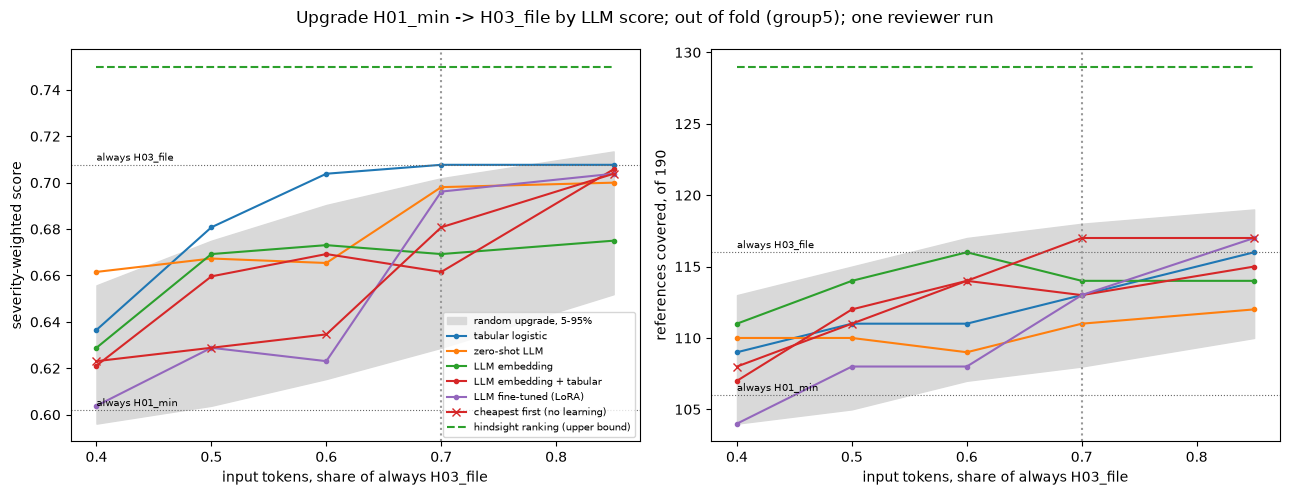

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, rcol in [(axes[0], "score_agreed", "score"), (axes[1], "covered", "covered")]:
    ax.fill_between(RANDOM_BUDGET.budget, RANDOM_BUDGET[f"{rcol}_p05"], RANDOM_BUDGET[f"{rcol}_p95"],
                    color="0.85", label="random upgrade, 5-95%")
    for name, fr in FRONTIERS.items():
        style = dict(ls="--", color="tab:green") if "hindsight" in name else \
                dict(marker="x", color="tab:red") if "cheapest" in name else dict(marker="o", ms=3)
        ax.plot(fr.budget, fr[metric], label=name, **style)
    for lv in (BASE_LEVEL, REF_LEVEL):
        r = FIXED.loc[LIDX[lv]]
        ax.axhline(r[metric], color="0.4", lw=0.8, ls=":")
        ax.annotate(f"always {lv}", (BUDGETS[0], r[metric]), fontsize=7, xytext=(0, 3), textcoords="offset points")
    ax.axvline(TARGET_BUDGET, color="0.6", ls=":")
    ax.set_xlabel(f"input tokens, share of always {REF_LEVEL}")
    ax.set_ylabel("severity-weighted score" if metric == "score_agreed" else f"references covered, of {R}")
axes[0].legend(fontsize=7, loc="lower right")
fig.suptitle(f"Upgrade {BASE_LEVEL} -> {UPGRADE_LEVEL} by LLM score; out of fold ({CV}); one reviewer run")
fig.tight_layout()
fig.savefig(OUT_DIR / "frontier_llm.png", dpi=160)
plt.show()

## 14. Paired, clustered bootstrap at the target budget

Score difference of each LLM method against always `H03_file`, cheapest first and the
tabular baseline, resampling repositories. The best method is chosen after looking, so
treat a single interval that excludes zero with caution.

In [15]:
def boot_diff(ch_a, ch_b, n=N_BOOT, seed=0):
    g = np.unique(REPOS); rng = np.random.default_rng(seed); w = W["agreed"]
    def cov(ch, r):
        idx = np.flatnonzero(REPOS == r)
        return COV[idx, ch[idx], :].any(0)
    rmask = {r: (refs_df["repo"] == r).to_numpy() for r in g}
    ca = {r: cov(ch_a, r) & rmask[r] for r in g}; cb = {r: cov(ch_b, r) & rmask[r] for r in g}
    num_a = {r: ca[r] @ w for r in g}; num_b = {r: cb[r] @ w for r in g}; den = {r: rmask[r] @ w for r in g}
    def diff(sample):
        d = sum(den[r] for r in sample)
        return (sum(num_a[r] for r in sample) - sum(num_b[r] for r in sample)) / d
    vals = [diff(rng.choice(g, size=len(g))) for _ in range(n)]
    return diff(g), *np.percentile(vals, [2.5, 97.5])

POL = {name: upgrade_choice(order_of(s), TARGET_BUDGET) for name, s in named.items()}
others = {f"always {REF_LEVEL}": fixed(REF_LEVEL), "cheapest first": POL["cheapest first (no learning)"],
          "tabular logistic": POL["tabular logistic"]}
cmp_rows = []
for name in SCORES:
    if name == "tabular logistic":
        continue
    for oname, och in others.items():
        d, lo, hi = boot_diff(POL[name], och)
        cmp_rows.append({"method": name, "versus": oname, "score_diff": d, "ci_low": lo, "ci_high": hi})
COMPARE = pd.DataFrame(cmp_rows)
print(COMPARE.round(3).to_string(index=False))

                 method           versus  score_diff  ci_low  ci_high
          zero-shot LLM  always H03_file      -0.010  -0.040    0.014
          zero-shot LLM   cheapest first       0.017  -0.029    0.078
          zero-shot LLM tabular logistic      -0.010  -0.028    0.014
          LLM embedding  always H03_file      -0.038  -0.118    0.015
          LLM embedding   cheapest first      -0.012  -0.086    0.037
          LLM embedding tabular logistic      -0.038  -0.112    0.018
LLM embedding + tabular  always H03_file      -0.046  -0.122    0.008
LLM embedding + tabular   cheapest first      -0.019  -0.085    0.028
LLM embedding + tabular tabular logistic      -0.046  -0.112    0.004
  LLM fine-tuned (LoRA)  always H03_file      -0.012  -0.032    0.004
  LLM fine-tuned (LoRA)   cheapest first       0.015  -0.025    0.076
  LLM fine-tuned (LoRA) tabular logistic      -0.012  -0.032    0.016


## 15. Human and AI references, tiers, context labels, categories

Answer-side fields are used here only, to group the evaluation, never as inputs.

In [16]:
def group_table(policies):
    out = []
    for name, ch in policies.items():
        covered = COV[np.arange(H), ch, :].any(0)
        row = {"policy": name}
        for col in ["human", "tier", "context", "category"]:
            for val, g in refs_df.groupby(col):
                row[f"{col}={val}"] = f"{covered[g.index].sum()}/{len(g)}"
        out.append(row)
    return pd.DataFrame(out).set_index("policy").T

policies = {f"always {BASE_LEVEL}": fixed(BASE_LEVEL), f"always {REF_LEVEL}": fixed(REF_LEVEL)}
policies.update({f"{k} @ {TARGET_BUDGET:.0%}": v for k, v in POL.items() if "hindsight" not in k})
GROUPS_TABLE = group_table(policies)
GROUPS_TABLE

policy,always H01_min,always H03_file,tabular logistic @ 70%,zero-shot LLM @ 70%,LLM embedding @ 70%,LLM embedding + tabular @ 70%,LLM fine-tuned (LoRA) @ 70%,cheapest first (no learning) @ 70%
human=False,89/143,96/143,94/143,92/143,94/143,95/143,93/143,99/143
human=True,17/47,20/47,19/47,19/47,20/47,18/47,20/47,18/47
tier=blocking,8/15,12/15,12/15,12/15,10/15,10/15,12/15,11/15
tier=nit,53/110,56/110,52/110,51/110,56/110,56/110,54/110,60/110
tier=should_fix,45/65,48/65,49/65,48/65,48/65,47/65,47/65,46/65
context=Diff Level,46/83,50/83,48/83,50/83,48/83,46/83,49/83,52/83
context=File Level,38/74,42/74,41/74,39/74,41/74,43/74,41/74,41/74
context=Repo Level,22/33,24/33,24/33,22/33,25/33,24/33,23/33,24/33
category=Code Defect,66/112,72/112,73/112,71/112,70/112,69/112,71/112,72/112
category=Maintainability and Readability,26/56,27/56,24/56,24/56,27/56,27/56,28/56,29/56


## 16. Save everything

In [17]:
def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

AUC.to_csv(OUT_DIR / "llm_upgrade_auc.csv", index=False)
BUDGET_TABLE.to_csv(OUT_DIR / "llm_budget_table.csv", index=False)
COMPARE.to_csv(OUT_DIR / "llm_bootstrap_comparisons.csv", index=False)
GROUPS_TABLE.to_csv(OUT_DIR / "llm_groups.csv")
RANDOM_BUDGET.to_csv(OUT_DIR / "random_upgrade_by_budget.csv", index=False)
oof = hunks[["hunk", "pr", "repo", "language", "file"]].copy()
oof["y_upgrade_helps"] = Y_UP
for name, s in SCORES.items():
    oof[f"score|{name}"] = s
for name, lst in SEED_SCORES.items():
    for seed, s in zip(FT_SEEDS, lst):
        oof[f"score|{name}|seed{seed}"] = s
oof.to_csv(OUT_DIR / "llm_oof_scores.csv", index=False)

manifest = {
    "written_at": time.strftime("%Y-%m-%dT%H:%M:%S%z"),
    "inputs": {k: str(v) for k, v in FILES.items()},
    "hunk_outcomes_sha256": sha256(FILES["outcomes"]), "contexts_sha256": sha256(FILES["contexts"]),
    "hunks": int(H), "references": int(R), "positives": int(Y_UP.sum()),
    "cv": CV, "folds": len(FOLDS), "base_level": BASE_LEVEL, "upgrade_level": UPGRADE_LEVEL,
    "target_weighting": TARGET_WEIGHTING, "budgets": BUDGETS, "n_random": N_RANDOM, "n_boot": N_BOOT,
    "llm_model": LLM_MODEL, "zero_shot_model": ZS_MODEL, "max_len": MAX_LEN, "diff_share": DIFF_SHARE,
    "use_meta": USE_META, "methods": list(SCORES),
    "finetune": {"seeds": FT_SEEDS, "epochs": FT_EPOCHS, "lr": FT_LR, "batch": FT_BATCH, "grad_acc": FT_GRAD_ACC,
                 "lora": [LORA_R, LORA_ALPHA, LORA_DROPOUT], "tag": FT_TAG} if RUN_FINETUNE else None,
    "versions": {"numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__,
                 "torch": torch.__version__, "transformers": transformers.__version__,
                 "python": sys.version.split()[0],
                 "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else DEVICE},
    "note": "Pilot on 15% of AACR-Bench (one reviewer run). Not a final result.",
}
(OUT_DIR / "llm_manifest.json").write_text(json.dumps(manifest, indent=1))
print("Saved to", OUT_DIR)
for p in sorted(OUT_DIR.iterdir()):
    print(" ", p.name)

Saved to /Users/penglihua/Desktop/GitHub/CS536_Project/results/selector_llm
  cache
  frontier_llm.png
  llm_bootstrap_comparisons.csv
  llm_budget_table.csv
  llm_groups.csv
  llm_manifest.json
  llm_oof_scores.csv
  llm_upgrade_auc.csv
  random_upgrade_by_budget.csv
  run_local.log
